## **Relationships**

This ipython serves for computing correlation and Cholesky decomposition between the variables.

In [1]:
# Import of necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import seaborn as sns

In [2]:
# Load data

# Inflation
infl = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/inflation/Inflation.xlsx")

# Exchange Rates
eur_czk = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/EUR_CZK.xlsx")
usd_czk = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/USD_CZK.xlsx")

# Stocks
pxtr = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/CZStocks.xlsx", sheet_name="PXTR")
sx5gt = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/EUStocks.xlsx", sheet_name="SX5GT")
spxtr = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/USStocks.xlsx", sheet_name="SPXTR")

# Bonds
czbond = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/CZBonds10YR.xlsx")
eubond = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/DEBonds10YR.xlsx")
usbond = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/USBonds10YR.xlsx")

In [3]:
# Shift Exchange rates one year lower to correspond to the rest of the data
eur_czk.loc[:, "Year"]=eur_czk["Year"]-1
usd_czk.loc[:, "Year"]=usd_czk["Year"]-1

In [4]:
# Prepare column names

# Exchange rates
eur_czk.rename({"Returns": "EUR"}, axis=1, inplace=True)
eur_czk=eur_czk[["Year", "EUR"]]
usd_czk.rename({"Returns": "USD"}, axis=1, inplace=True)
usd_czk=usd_czk[["Year", "USD"]]

# Stocks
pxtr.rename({"%Chg": "PXTR"}, axis=1, inplace=True)
pxtr=pxtr[["Year", "PXTR"]]
sx5gt.rename({"%Chg": "SX5GT"}, axis=1, inplace=True)
sx5gt=sx5gt[["Year", "SX5GT"]]
spxtr.rename({"%Chg": "SPXTR"}, axis=1, inplace=True)
spxtr=spxtr[["Year", "SPXTR"]]

# Bonds
czbond.rename({"Return": "CZBond"}, axis=1, inplace=True)
czbond=czbond[["Year", "CZBond"]]
eubond.rename({"Return": "EUBond"}, axis=1, inplace=True)
eubond=eubond[["Year", "EUBond"]]
usbond.rename({"Return": "USBond"}, axis=1, inplace=True)
usbond=usbond[["Year", "USBond"]]


In [5]:
# List of all dataframes (except for inflation)
df_list = [eur_czk, usd_czk, pxtr, sx5gt, spxtr, czbond, eubond, usbond]

# Outer join all data
data = df_list[0]
for df in df_list[1:]:
    data = pd.merge(data, df, on='Year', how='outer')
    
# Set "Year" as an index
data.set_index("Year", inplace=True)

In [6]:
# Compute Correlation matrix
corr_matrix = data.corr()

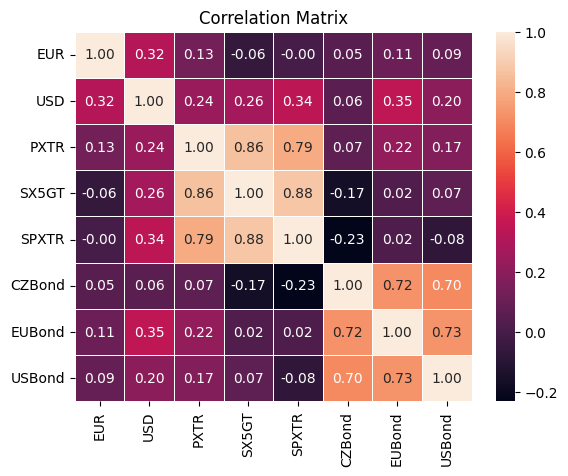

In [10]:
# Visualize Correlation Matrix
plt.Figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Relationships/Corr_matrix.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [15]:
# Cholesky decomposition calculation from covariance matrix
chol_deco = np.linalg.cholesky(data.cov())

# Save matrix
np.save("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/relationships/cholesky_decomposition.npy", chol_deco)

# Visualize
chol_deco = pd.DataFrame(chol_deco)
chol_deco.columns = ['']*chol_deco.shape[1]
print(chol_deco.to_string(index=False))

                                                                          
 0.037929 0.000000 0.000000  0.000000  0.000000 0.000000 0.000000 0.000000
 0.028123 0.100899 0.000000  0.000000  0.000000 0.000000 0.000000 0.000000
 0.028249 0.030551 0.227428  0.000000  0.000000 0.000000 0.000000 0.000000
-0.011511 0.049512 0.151706  0.107115  0.000000 0.000000 0.000000 0.000000
-0.000412 0.063430 0.138834  0.061243  0.062640 0.000000 0.000000 0.000000
 0.026657 0.016228 0.032568 -0.202005 -0.251067 0.439527 0.000000 0.000000
 0.072711 0.172194 0.140105 -0.240154 -0.206284 0.333139 0.516934 0.000000
 0.031404 0.045271 0.056653 -0.054790 -0.197377 0.175128 0.042665 0.235598


In [ ]:
# Check that Covariance Matrix is positive definite
np.all(np.linalg.eigvals(data.cov()) > 0) 

np.True_